In [6]:
#!pip install matplotlib
#%matplotlib inline
#!pip install seaborn

In [7]:
from pathlib import Path
try:
    ROOT = Path(__file__).resolve().parent   # script na raiz do projeto
except NameError:
    ROOT = Path.cwd()                        # notebook aberto na raiz do projeto
import numpy as np
import pandas as pd
import sys
import matplotlib
EM_NOTEBOOK = "ipykernel" in sys.modules      # True dentro do Jupyter / VS Code
if EM_NOTEBOOK:
    from IPython import get_ipython
    get_ipython().run_line_magic("matplotlib", "inline")   # garante backend que exibe (desfaz um Agg antigo)
else:
    matplotlib.use("Agg")                     # script puro: só grava os PNGs
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
 
SRC = ROOT / "dados" / "gold" / "history_gold.csv"
OUT = ROOT / "graficos"
OUT.mkdir(exist_ok=True)
 
BLUE, RED, GRAY, GREEN, ORANGE = "#4C78A8", "#E45756", "#B0B7C3", "#54A24B", "#F58518"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
 
# ---------------------------------------------------------------- dados
g = pd.read_csv(SRC)
g["Contrato_PT"] = g.Contrato.map({"Month-to-month": "Mensal", "One year": "1 ano", "Two year": "2 anos"})
g["Internet_PT"] = g.Servico_Internet.map({"Fiber optic": "Fibra", "DSL": "DSL", "No": "Sem internet"})
g["Pagamento_PT"] = g.Metodo_Pagamento.map({
    "Electronic check": "Cheque eletrônico", "Mailed check": "Cheque correio",
    "Bank transfer (automatic)": "Transf. automática", "Credit card (automatic)": "Cartão automático"})
ORD_C = ["Mensal", "1 ano", "2 anos"]
ORD_I = ["Fibra", "DSL", "Sem internet"]
ORD_P = ["Cheque eletrônico", "Cheque correio", "Transf. automática", "Cartão automático"]
ORD_F = ["0-6", "7-12", "13-24", "25-48", "48+"]
MRR = g.Cobranca_Mensal.sum()
net = g[g.Servico_Internet != "No"]
 
 
def br(v, d=0):
    s = f"{v:,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")
 
 
def save(fig, name):
    fig.savefig(OUT / name, dpi=150, bbox_inches="tight", facecolor="white")
    if EM_NOTEBOOK:
        plt.show()                            # exibe o gráfico embaixo da célula
    plt.close(fig)

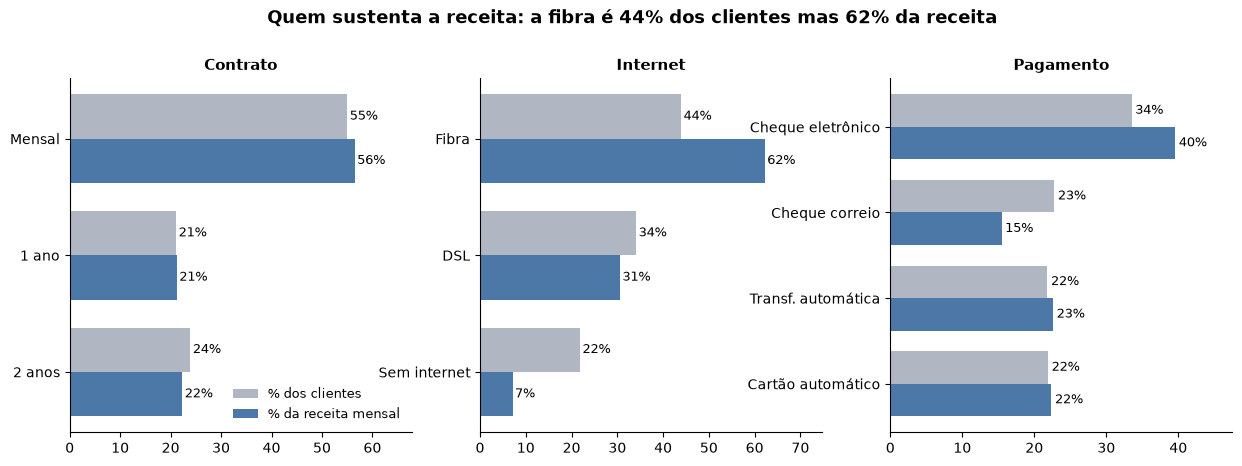

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (col, tit, order) in zip(axes, [("Contrato_PT", "Contrato", ORD_C),
                                        ("Internet_PT", "Internet", ORD_I),
                                        ("Pagamento_PT", "Pagamento", ORD_P)]):
    t = g.groupby(col).agg(n=("ID_Cliente", "size"), mrr=("Cobranca_Mensal", "sum")).reindex(order)
    cli, rec = t.n / t.n.sum() * 100, t.mrr / t.mrr.sum() * 100
    y, h = np.arange(len(t)), 0.38
    ax.barh(y - h / 2, cli, h, color=GRAY, label="% dos clientes")
    ax.barh(y + h / 2, rec, h, color=BLUE, label="% da receita mensal")
    for i, (a, b) in enumerate(zip(cli, rec)):
        ax.text(a + 0.5, i - h / 2, f"{a:.0f}%", va="center", fontsize=9)
        ax.text(b + 0.5, i + h / 2, f"{b:.0f}%", va="center", fontsize=9)
    ax.set_yticks(y)
    ax.set_yticklabels(order)
    ax.invert_yaxis()
    ax.set_xlim(0, max(cli.max(), rec.max()) * 1.2)
    ax.set_title(tit)
axes[0].legend(loc="lower right", frameon=False, fontsize=9)
fb = g[g.Servico_Internet == "Fiber optic"]
fig.suptitle(f"Quem sustenta a receita: a fibra é {fb.shape[0] / len(g) * 100:.0f}% dos clientes mas "
             f"{fb.Cobranca_Mensal.sum() / MRR * 100:.0f}% da receita", fontsize=13, fontweight="bold", y=1.03)
save(fig, "01_composicao_carteira.png")

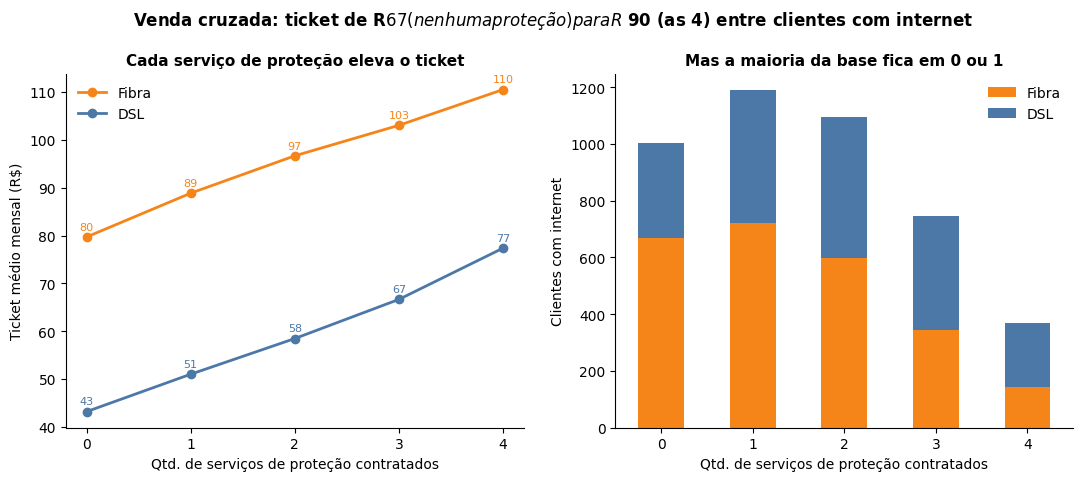

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
t = net.groupby(["Qtd_Servicos_Protecao", "Internet_PT"]).Cobranca_Mensal.mean().unstack()
for col, color in [("Fibra", ORANGE), ("DSL", BLUE)]:
    axes[0].plot(t.index, t[col], marker="o", color=color, label=col, lw=2)
    for x, v in t[col].items():
        axes[0].text(x, v + 1.5, f"{v:.0f}", ha="center", fontsize=8, color=color)
axes[0].set_xticks(range(5))
axes[0].set_xlabel("Qtd. de serviços de proteção contratados")
axes[0].set_ylabel("Ticket médio mensal (R$)")
axes[0].set_title("Cada serviço de proteção eleva o ticket")
axes[0].legend(frameon=False)
c = net.groupby(["Qtd_Servicos_Protecao", "Internet_PT"]).size().unstack().fillna(0)
c[["Fibra", "DSL"]].plot.bar(stacked=True, ax=axes[1], color=[ORANGE, BLUE], rot=0)
axes[1].set_xlabel("Qtd. de serviços de proteção contratados")
axes[1].set_ylabel("Clientes com internet")
axes[1].set_title("Mas a maioria da base fica em 0 ou 1")
axes[1].legend(frameon=False)
tk0 = net[net.Qtd_Servicos_Protecao == 0].Cobranca_Mensal.mean()
tk4 = net[net.Qtd_Servicos_Protecao == 4].Cobranca_Mensal.mean()
fig.suptitle(f"Venda cruzada: ticket de R$ {br(tk0)} (nenhuma proteção) para R$ {br(tk4)} (as 4) entre clientes com internet",
             fontsize=12, fontweight="bold", y=1.02)
save(fig, "02_valor_dos_servicos.png")

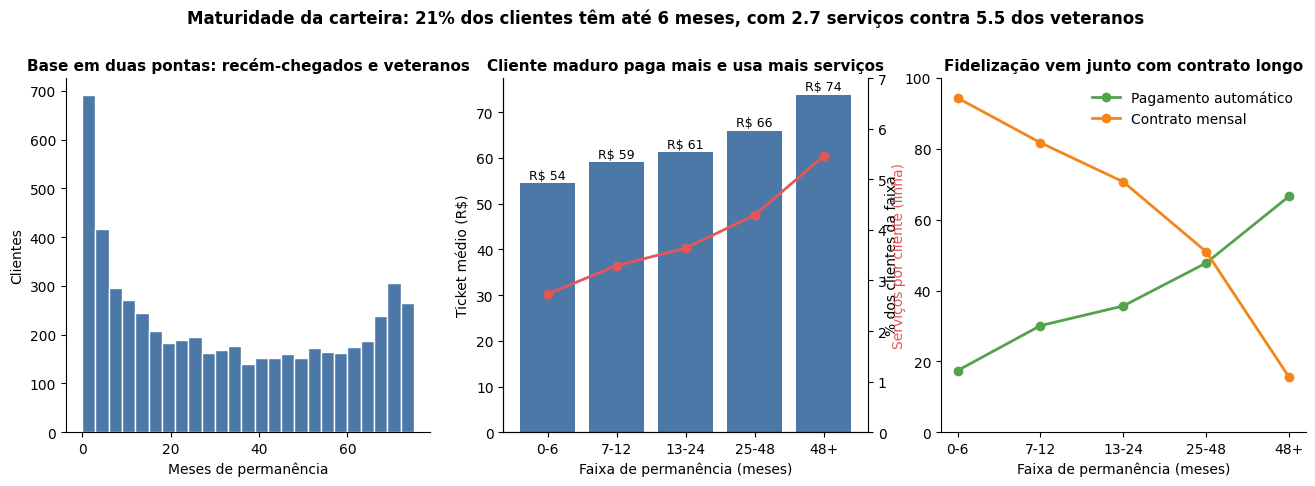

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].hist(g.Tempo_Permanencia_Meses, bins=np.arange(0, 76, 3), color=BLUE, edgecolor="white")
axes[0].set_xlabel("Meses de permanência")
axes[0].set_ylabel("Clientes")
axes[0].set_title("Base em duas pontas: recém-chegados e veteranos")
f = g.groupby("Faixa_Permanencia").agg(tk=("Cobranca_Mensal", "mean"), sv=("Qtd_Servicos_Total", "mean"),
                                       pa=("Pagamento_Automatico", "mean"),
                                       mes=("Contrato", lambda s: (s == "Month-to-month").mean())).reindex(ORD_F)
axes[1].bar(ORD_F, f.tk, color=BLUE)
for i, v in enumerate(f.tk):
    axes[1].text(i, v + 1, f"R$ {v:.0f}", ha="center", fontsize=9)
ax2 = axes[1].twinx()
ax2.plot(ORD_F, f.sv, color=RED, marker="o", lw=2)
ax2.set_ylim(0, 7)
ax2.set_ylabel("Serviços por cliente (linha)", color=RED)
ax2.spines["right"].set_visible(True)
axes[1].set_xlabel("Faixa de permanência (meses)")
axes[1].set_ylabel("Ticket médio (R$)")
axes[1].set_title("Cliente maduro paga mais e usa mais serviços")
axes[2].plot(ORD_F, f.pa * 100, marker="o", color=GREEN, lw=2, label="Pagamento automático")
axes[2].plot(ORD_F, f.mes * 100, marker="o", color=ORANGE, lw=2, label="Contrato mensal")
axes[2].set_ylim(0, 100)
axes[2].set_ylabel("% dos clientes da faixa")
axes[2].set_xlabel("Faixa de permanência (meses)")
axes[2].set_title("Fidelização vem junto com contrato longo")
axes[2].legend(frameon=False)
n06 = (g.Faixa_Permanencia == "0-6").mean() * 100
fig.suptitle(f"Maturidade da carteira: {n06:.0f}% dos clientes têm até 6 meses, com {f.sv['0-6']:.1f} serviços contra {f.sv['48+']:.1f} dos veteranos",
             fontsize=12, fontweight="bold", y=1.03)
save(fig, "03_maturidade_da_base.png")

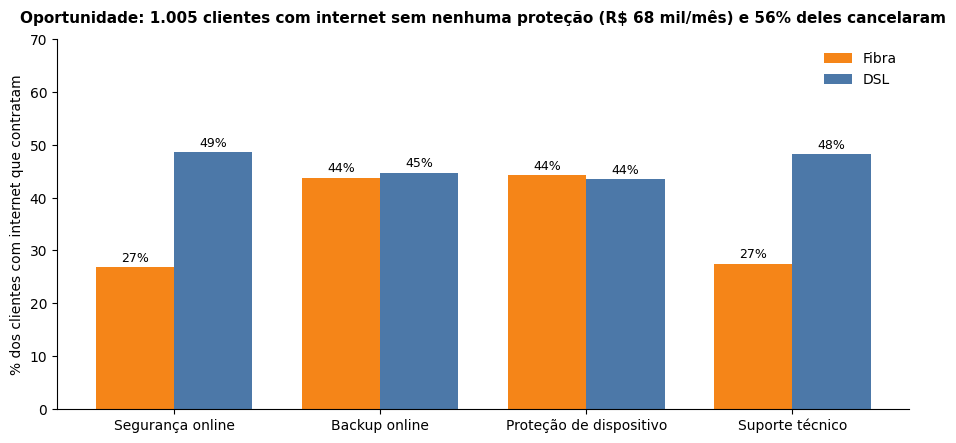

In [ ]:
cols = {"Seguranca_Online": "Segurança online", "Backup_Online": "Backup online",
        "Protecao_Dispositivo": "Proteção de dispositivo", "Suporte_Tecnico": "Suporte técnico"}
fig, ax = plt.subplots(figsize=(11, 4.8))
p = net.groupby("Internet_PT")[list(cols)].mean().T * 100
p.index = [cols[i] for i in p.index]
p = p[["Fibra", "DSL"]]
x, h = np.arange(len(p)), 0.38
b1 = ax.bar(x - h / 2, p.Fibra, h, color=ORANGE, label="Fibra")
b2 = ax.bar(x + h / 2, p.DSL, h, color=BLUE, label="DSL")
for bars in (b1, b2):
    ax.bar_label(bars, fmt="%.0f%%", padding=2, fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(p.index)
ax.set_ylabel("% dos clientes com internet que contratam")
ax.set_ylim(0, 70)
ax.legend(frameon=False)
sem = net[net.Qtd_Servicos_Protecao == 0]
ax.set_title(f"Oportunidade: {len(sem):,} clientes com internet sem nenhuma proteção (R$ {br(sem.Cobranca_Mensal.sum() / 1000)} mil/mês) "
             f"e {sem.Cancelou.mean() * 100:.0f}% deles cancelaram".replace(",", "."), fontsize=11, pad=12)
save(fig, "04_oportunidade_venda_cruzada.png")

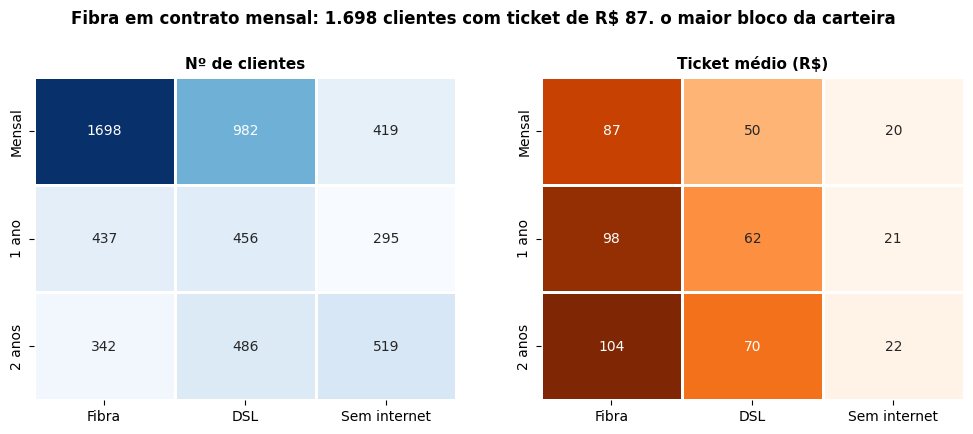

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
q = g.pivot_table(index="Contrato_PT", columns="Internet_PT", values="ID_Cliente", aggfunc="count").loc[ORD_C, ORD_I]
tk = g.pivot_table(index="Contrato_PT", columns="Internet_PT", values="Cobranca_Mensal", aggfunc="mean").loc[ORD_C, ORD_I]
sns.heatmap(q, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0], linewidths=1)
axes[0].set_title("Nº de clientes")
sns.heatmap(tk, annot=True, fmt=".0f", cmap="Oranges", cbar=False, ax=axes[1], linewidths=1)
axes[1].set_title("Ticket médio (R$)")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle(f"Fibra em contrato mensal: {q.loc['Mensal', 'Fibra']:,} clientes com ticket de R$ {tk.loc['Mensal', 'Fibra']:.0f}, o maior bloco da carteira".replace(",", "."),
             fontsize=12, fontweight="bold", y=1.04)
save(fig, "05_mapa_contrato_internet.png")

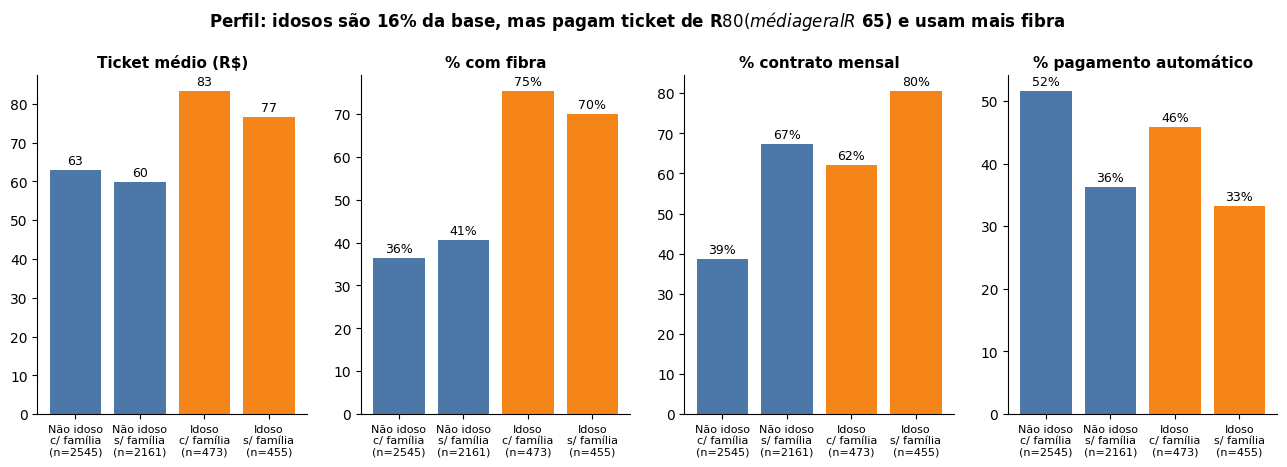

In [ ]:
g["Seg"] = np.where(g.Cliente_Idoso == 1, "Idoso", "Não idoso") + "\n" + np.where(g.Tem_Familia == 1, "c/ família", "s/ família")
ORD_S = ["Não idoso\nc/ família", "Não idoso\ns/ família", "Idoso\nc/ família", "Idoso\ns/ família"]
s = g.groupby("Seg").agg(n=("ID_Cliente", "size"), tk=("Cobranca_Mensal", "mean"),
                         fib=("Servico_Internet", lambda v: (v == "Fiber optic").mean() * 100),
                         mes=("Contrato", lambda v: (v == "Month-to-month").mean() * 100),
                         pa=("Pagamento_Automatico", lambda v: v.mean() * 100)).reindex(ORD_S)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, (col, tit, fmt) in zip(axes, [("tk", "Ticket médio (R$)", "{:.0f}"), ("fib", "% com fibra", "{:.0f}%"),
                                      ("mes", "% contrato mensal", "{:.0f}%"), ("pa", "% pagamento automático", "{:.0f}%")]):
    bars = ax.bar(range(4), s[col], color=[BLUE, BLUE, ORANGE, ORANGE])
    ax.bar_label(bars, labels=[fmt.format(v) for v in s[col]], padding=2, fontsize=9)
    ax.set_xticks(range(4))
    ax.set_xticklabels([f"{i}\n(n={n})" for i, n in zip(ORD_S, s.n)], fontsize=8)
    ax.set_title(tit)
idoso = g[g.Cliente_Idoso == 1]
fig.suptitle(f"Perfil: idosos são {len(idoso) / len(g) * 100:.0f}% da base, mas pagam ticket de R$ {idoso.Cobranca_Mensal.mean():.0f} "
             f"(média geral R$ {g.Cobranca_Mensal.mean():.0f}) e usam mais fibra", fontsize=12, fontweight="bold", y=1.03)
save(fig, "06_perfil_demografico.png")

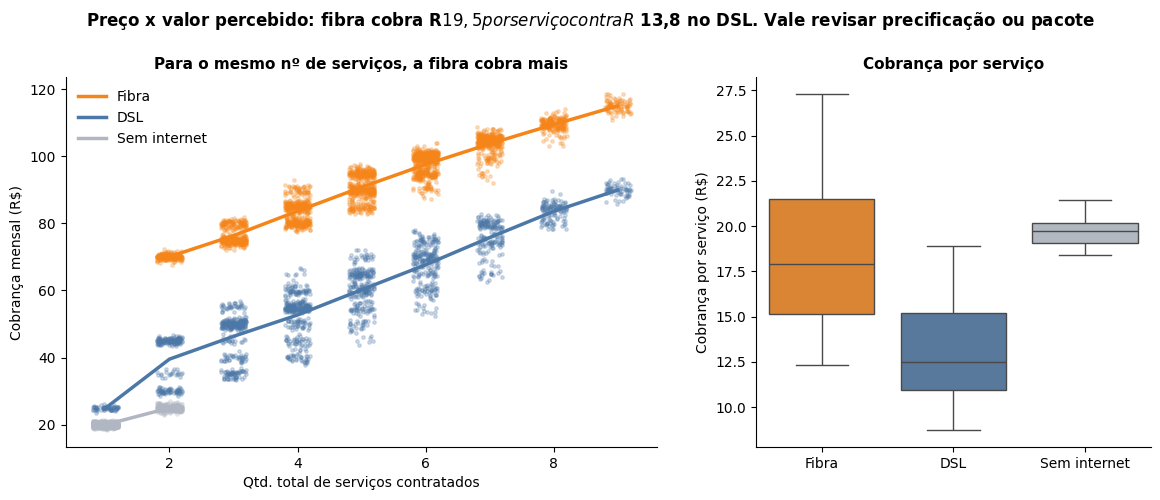

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
rng = np.random.default_rng(0)
for nome, color in [("Fibra", ORANGE), ("DSL", BLUE), ("Sem internet", GRAY)]:
    d = g[g.Internet_PT == nome]
    axes[0].scatter(d.Qtd_Servicos_Total + rng.uniform(-0.2, 0.2, len(d)), d.Cobranca_Mensal, s=6, alpha=0.25, color=color)
    m = d.groupby("Qtd_Servicos_Total").Cobranca_Mensal.mean()
    axes[0].plot(m.index, m.values, color=color, lw=2.5, label=nome)
axes[0].set_xlabel("Qtd. total de serviços contratados")
axes[0].set_ylabel("Cobrança mensal (R$)")
axes[0].set_title("Para o mesmo nº de serviços, a fibra cobra mais")
axes[0].legend(frameon=False)
order = ["Fibra", "DSL", "Sem internet"]
sns.boxplot(data=g, x="Internet_PT", y="Cobranca_Por_Servico", hue="Internet_PT", order=order, hue_order=order,
            palette=[ORANGE, BLUE, GRAY], legend=False, ax=axes[1], showfliers=False)
axes[1].set_xlabel("")
axes[1].set_ylabel("Cobrança por serviço (R$)")
axes[1].set_title("Cobrança por serviço")
mf, md = g[g.Internet_PT == "Fibra"].Cobranca_Por_Servico.mean(), g[g.Internet_PT == "DSL"].Cobranca_Por_Servico.mean()
fig.suptitle(f"Preço x valor percebido: fibra cobra R$ {br(mf, 1)} por serviço contra R$ {br(md, 1)} no DSL. Vale revisar precificação ou pacote",
             fontsize=12, fontweight="bold", y=1.02)
save(fig, "07_preco_vs_valor.png")

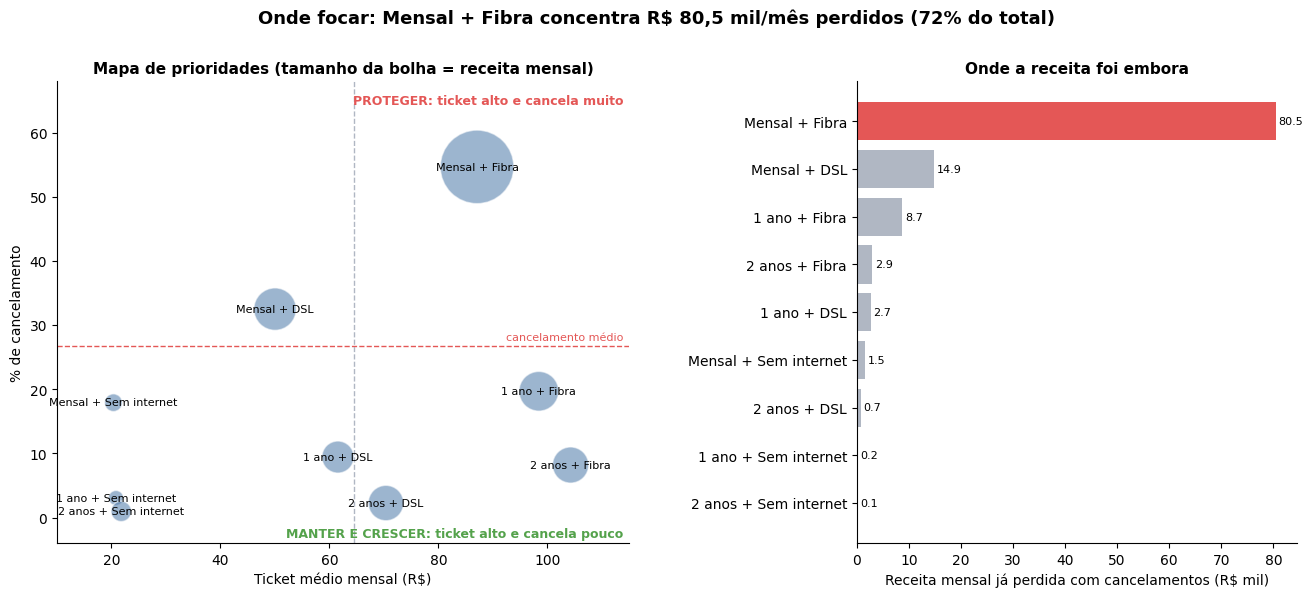

In [ ]:
g["Seg9"] = g.Contrato_PT + " + " + g.Internet_PT
sg = g.groupby("Seg9").agg(n=("ID_Cliente", "size"), mrr=("Cobranca_Mensal", "sum"), tk=("Cobranca_Mensal", "mean"),
                           ch=("Cancelou", "mean"))
sg["perdido"] = g[g.Cancelou == 1].groupby("Seg9").Cobranca_Mensal.sum()
sg = sg.fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.45})
ax = axes[0]
ax.scatter(sg.tk, sg.ch * 100, s=sg.mrr / sg.mrr.max() * 2800, color=BLUE, alpha=0.55, edgecolor="white")
for nome, r in sg.iterrows():
    ax.annotate(nome, (r.tk, r.ch * 100), ha="center", va="center", fontsize=8)
ax.axhline(g.Cancelou.mean() * 100, color=RED, ls="--", lw=1)
ax.axvline(g.Cobranca_Mensal.mean(), color=GRAY, ls="--", lw=1)
ax.set_xlim(10, 115)
ax.set_ylim(-4, 68)
ax.text(114, g.Cancelou.mean() * 100 + 1, "cancelamento médio", ha="right", color=RED, fontsize=8)
ax.text(114, 66, "PROTEGER: ticket alto e cancela muito", ha="right", va="top", color=RED, fontsize=9, fontweight="bold")
ax.text(114, -2.5, "MANTER E CRESCER: ticket alto e cancela pouco", ha="right", va="center", color=GREEN, fontsize=9, fontweight="bold")
ax.set_xlabel("Ticket médio mensal (R$)")
ax.set_ylabel("% de cancelamento")
ax.set_title("Mapa de prioridades (tamanho da bolha = receita mensal)")
top = sg.sort_values("perdido")
axes[1].barh(top.index, top.perdido / 1000, color=[RED if v == top.perdido.max() else GRAY for v in top.perdido])
axes[1].bar_label(axes[1].containers[0], fmt="%.1f", padding=2, fontsize=8)
axes[1].set_xlabel("Receita mensal já perdida com cancelamentos (R$ mil)")
axes[1].set_title("Onde a receita foi embora")
mp = sg.perdido.idxmax()
fig.suptitle(f"Onde focar: {mp} concentra R$ {br(sg.perdido.max() / 1000, 1)} mil/mês perdidos "
             f"({sg.perdido.max() / sg.perdido.sum() * 100:.0f}% do total)", fontsize=13, fontweight="bold", y=1.0)
save(fig, "08_onde_focar.png")

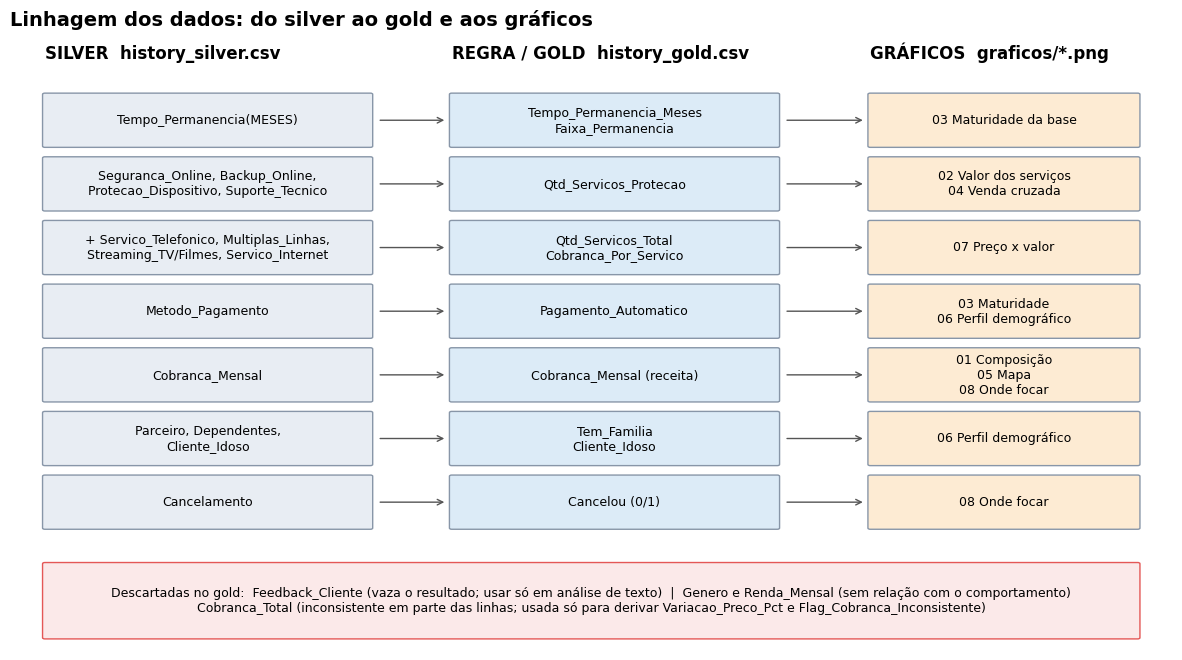

ok ['01_composicao_carteira.png', '02_valor_dos_servicos.png', '03_maturidade_da_base.png', '04_oportunidade_venda_cruzada.png', '05_mapa_contrato_internet.png', '06_perfil_demografico.png', '07_preco_vs_valor.png', '08_onde_focar.png', '09_linhagem_dos_dados.png']


In [ ]:
fig, ax = plt.subplots(figsize=(15, 8))
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")
rows = [
    ("Tempo_Permanencia(MESES)", "Tempo_Permanencia_Meses\nFaixa_Permanencia", "03 Maturidade da base"),
    ("Seguranca_Online, Backup_Online,\nProtecao_Dispositivo, Suporte_Tecnico", "Qtd_Servicos_Protecao", "02 Valor dos serviços\n04 Venda cruzada"),
    ("+ Servico_Telefonico, Multiplas_Linhas,\nStreaming_TV/Filmes, Servico_Internet", "Qtd_Servicos_Total\nCobranca_Por_Servico", "07 Preço x valor"),
    ("Metodo_Pagamento", "Pagamento_Automatico", "03 Maturidade\n06 Perfil demográfico"),
    ("Cobranca_Mensal", "Cobranca_Mensal (receita)", "01 Composição\n05 Mapa\n08 Onde focar"),
    ("Parceiro, Dependentes,\nCliente_Idoso", "Tem_Familia\nCliente_Idoso", "06 Perfil demográfico"),
    ("Cancelamento", "Cancelou (0/1)", "08 Onde focar"),
]
heads = [(3, "SILVER  history_silver.csv"), (38, "REGRA / GOLD  history_gold.csv"), (74, "GRÁFICOS  graficos/*.png")]
for x0, t in heads:
    ax.text(x0, 96, t, fontsize=12, fontweight="bold")
ys = np.linspace(86, 24, len(rows))
for y, (a, b, c) in zip(ys, rows):
    for x0, w, txt, col in [(3, 28, a, "#E8EDF3"), (38, 28, b, "#DCEBF7"), (74, 23, c, "#FDEBD3")]:
        ax.add_patch(FancyBboxPatch((x0, y - 4.2), w, 8.4, boxstyle="round,pad=0.2", fc=col, ec="#8896A8", lw=1))
        ax.text(x0 + w / 2, y, txt, ha="center", va="center", fontsize=9)
    ax.annotate("", xy=(37.6, y), xytext=(31.6, y), arrowprops=dict(arrowstyle="->", color="#555"))
    ax.annotate("", xy=(73.6, y), xytext=(66.6, y), arrowprops=dict(arrowstyle="->", color="#555"))
ax.add_patch(FancyBboxPatch((3, 2), 94, 12, boxstyle="round,pad=0.2", fc="#FBE9E9", ec=RED, lw=1))
ax.text(50, 8, "Descartadas no gold:  Feedback_Cliente (vaza o resultado; usar só em análise de texto)  |  Genero e Renda_Mensal (sem relação com o comportamento)\n"
               "Cobranca_Total (inconsistente em parte das linhas; usada só para derivar Variacao_Preco_Pct e Flag_Cobranca_Inconsistente)",
        ha="center", va="center", fontsize=9)
ax.set_title("Linhagem dos dados: do silver ao gold e aos gráficos", fontsize=14, fontweight="bold", loc="left")
save(fig, "09_linhagem_dos_dados.png")
print("ok", sorted(p.name for p in OUT.glob("*.png")))